## load CIFAR10 data from kaggle

In [ ]:
# load CIFAR10 data from kaggle
import os
from google.colab import files

# 1. Upload your kaggle.json file
uploaded = files.upload()

# 2. Create the ~/.kaggle directory if it doesn't exist
os.makedirs('/root/.kaggle', exist_ok=True)

# 3. Move the uploaded kaggle.json file to ~/.kaggle/
!mv kaggle.json /root/.kaggle/

# 4. Set appropriate file permissions (read/write for owner only)
!chmod 600 /root/.kaggle/kaggle.json

print("Kaggle API key configured successfully!")

Saving kaggle_api.json to kaggle_api.json
mv: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Kaggle API key configured successfully!


In [ ]:
# Install Kaggle library if not already installed
!pip install -q kaggle

# Download the dataset (replace with your dataset's API command)
!kaggle datasets download -d fedesoriano/cifar10-python-in-csv

# Unzip the downloaded dataset into a specific directory
import zipfile

dataset_zip = "cifar10-python-in-csv.zip"  # Replace with the actual zip filename downloaded

with zipfile.ZipFile(dataset_zip, 'r') as zip_ref:
    zip_ref.extractall('dataset_folder')

print("Dataset downloaded and extracted!")

Dataset URL: https://www.kaggle.com/datasets/fedesoriano/cifar10-python-in-csv
License(s): copyright-authors
100% 209M/209M [00:12<00:00, 17.4MB/s]

Dataset downloaded and extracted!


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from torchvision import datasets, transforms

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available()  else "cpu")

In [ ]:
train = pd.read_csv('dataset_folder/train.csv')
test = pd.read_csv('dataset_folder/test.csv')

In [ ]:
train.shape, test.shape

((50000, 3073), (10000, 3072))

In [ ]:
x_train = train.iloc[:, :-1]
y_train = train.iloc[:, -1]
x_test = test.copy()

In [ ]:
x_train.shape, y_train.shape, x_test.shape

((50000, 3072), (50000,), (10000, 3072))

In [ ]:
x_train, x_val, y_train, y_val = train_test_split(x_train, y_train, test_size=10000, random_state = 3)

In [ ]:
x_train.shape, x_val.shape, y_train.shape, y_val.shape

((40000, 3072), (10000, 3072), (40000,), (10000,))

Create a transformer function that takes a 32x32 image and applies random transformations like cropping, horizontal flip, rotations, and some modifications with brightness, contrast, etc.


In [ ]:

tf = transforms.Compose([
    transforms.RandomCrop(size = 32, padding = 3, padding_mode='reflect'),  #random crop
    transforms.RandomHorizontalFlip(p = 0.5), #horizontal flip
    transforms.RandomRotation(degrees = 15),  #rotate +-15 degrees
    transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1),
])

tf

Compose(
    RandomCrop(size=(32, 32), padding=3)
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-15.0, 15.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=(0.9, 1.1), contrast=(0.9, 1.1), saturation=(0.9, 1.1), hue=None)
)

- Using this above function, the transformations are applied on-the-fly when the data is requested, so no extra memory required

In [ ]:
class d_set(Dataset):

  def __init__(self, x: np.ndarray, y: np.ndarray, transform = None):

    self.x = torch.tensor(x, dtype = torch.float)
    self.y = torch.tensor(y, dtype=torch.long)
    self.transform = transform

  def __getitem__(self, index):
    img =  self.x[index].reshape(3, 32, 32)
    label = self.y[index]

    if self.transform:
      img = self.transform(img)

    return img, label

  def __len__(self):
    return self.x.shape[0]

In [ ]:
train_set = d_set(x_train.values, y_train.values, tf)  # transformations should be applied only on training set
val_set = d_set(x_val.values, y_val.values)

In [ ]:
#iterable dataloaders
train_loader = DataLoader(train_set, batch_size=128, shuffle = True)  #shuffle at the start of each epoch
val_loader = DataLoader(val_set, batch_size=128, shuffle = True)  #shuffle at the start of each epoch

In [ ]:
len(train_set), len(val_set)

(40000, 10000)

- Note that the dataset size is still the same.
- Transformations are applied only when the data is requested for training.

In [ ]:
class_map = {
    0: "airplane",
    1: "automobile",
    2: "bird",
    3: "cat",
    4: "deer",
    5: "dog",
    6: "frog",
    7: "horse",
    8: "ship",
    9: "truck"
}

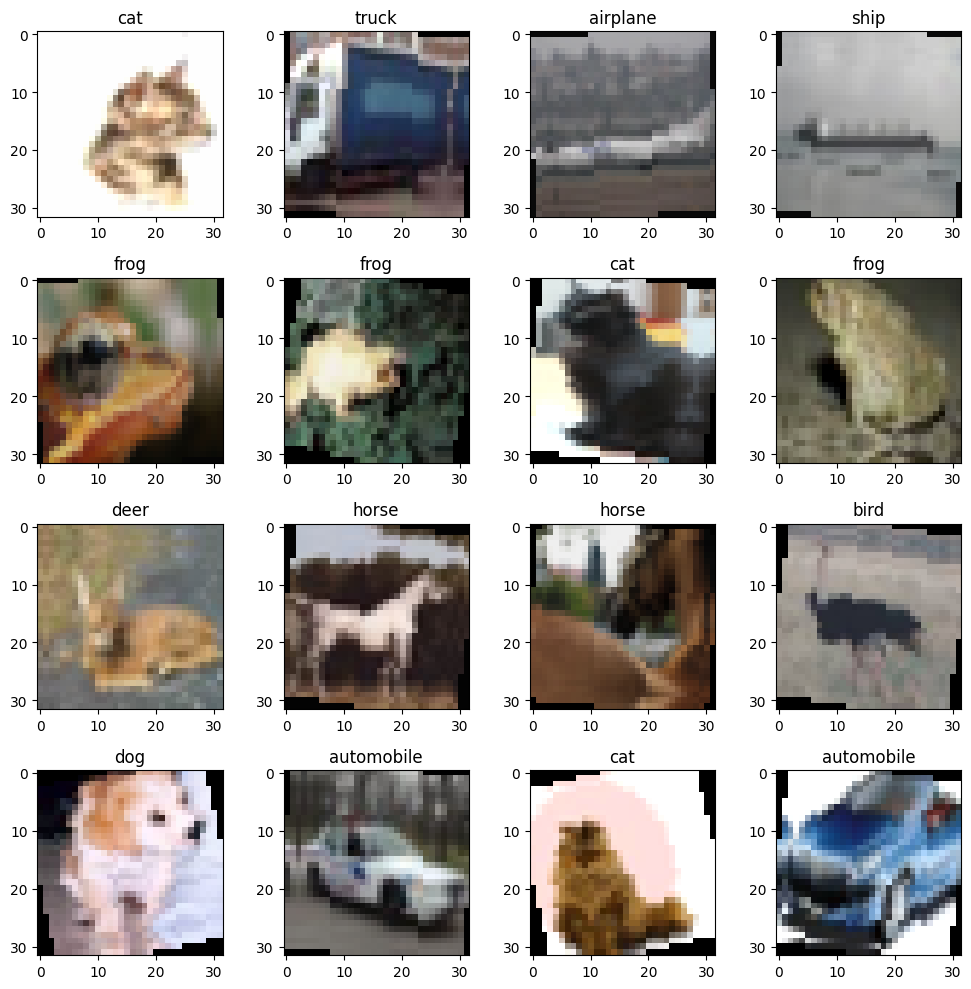

In [ ]:
plt.figure(figsize = (10, 10))
for i in range(16):
  plt.subplot(4,4, i+1)
  plt.imshow(train_set[i][0].permute(1, 2, 0))
  #                            ch, hieght, width -> h, w, ch
  plt.title(f"{class_map[train_set[i][1].item()]}")

plt.tight_layout()
plt.show()


In [ ]:
class CNN(nn.Module):

  def __init__(self, in_channels):
    super().__init__()

      # defining our network architecture
    self.feature_layer = nn.Sequential(
        #requires a box of images (n, 3, 32, 32) as input
        nn.Conv2d(in_channels=in_channels, out_channels=32, kernel_size=3, padding = "same"),
        nn.BatchNorm2d(32),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2),

        nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding = "valid"),
        nn.BatchNorm2d(64),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2)
    )

    self.classif_layer = nn.Sequential(
        nn.Flatten(),

        nn.Linear(7*7*64, 784),
        nn.ReLU(),
        nn.Dropout(0.1),

        nn.Linear(784, 196),
        nn.ReLU(),
        nn.Dropout(0.2),

        nn.Linear(196, 10),
    )

  def forward(self, x):
    features = self.feature_layer(x)  #conv layer
    return self.classif_layer(features) #output layer

In [ ]:
model = CNN(3)
model = model.to(device)
lr = 0.001
optim = torch.optim.Adam(model.parameters(), lr = lr, weight_decay=5e-5)
loss_func = nn.CrossEntropyLoss()

In [ ]:
# train loop

# for Early Stopping
patience = 5
patience_counter = 0
best_val_loss = float('inf')
best_model_weights = None

epochs = 50

for e in range(epochs):
  # ------------------ TRAINING PHASE ------------------
  model.train()
  train_loss = 0.0

  for batch_x, batch_y in train_loader:
      # Move data to GPU
      batch_x, batch_y = batch_x.to(device), batch_y.to(device)

      # Forward pass
      y_pred = model(batch_x)
      loss = loss_func(y_pred, batch_y)

      # Backward propagation
      optim.zero_grad()
      loss.backward()

      # Update weights
      optim.step()

      train_loss += loss.item()

  avg_train_loss = train_loss / len(train_loader)

  # ------------------ VALIDATION PHASE ------------------
  model.eval()
  val_loss = 0.0

  with torch.no_grad():
      for batch_x, batch_y in val_loader:
          batch_x, batch_y = batch_x.to(device), batch_y.to(device)
          y_pred = model(batch_x)
          loss = loss_func(y_pred, batch_y)
          val_loss += loss.item()

  avg_val_loss = val_loss / len(val_loader)

  # Print epoch progress
  print(f"Epoch {e+1:02d}/{epochs:02d} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f}")

  # ------------------ EARLY STOPPING LOGIC ------------------
  if avg_val_loss < best_val_loss:
      best_val_loss = avg_val_loss
      patience_counter = 0
      # Save the best model parameters
      best_model_weights = model.state_dict().copy()
      print(f"--> Val loss improved! Saving best weights.")
  else:
      patience_counter += 1
      print(f"--> No improvement in val loss ({patience_counter}/{patience})")

  if patience_counter >= patience:
      print(f"\n[Early Stopping Triggered] Stopped early at epoch {e+1}.")
      break

# Restore best weights after training stops
if best_model_weights is not None:
    model.load_state_dict(best_model_weights)
    print("Loaded best model weights into model!")

Epoch 01/50 | Train Loss: 1.5525 | Val Loss: 1.2561
--> Val loss improved! Saving best weights.
Epoch 02/50 | Train Loss: 1.2669 | Val Loss: 1.0675
--> Val loss improved! Saving best weights.
Epoch 03/50 | Train Loss: 1.1670 | Val Loss: 1.0084
--> Val loss improved! Saving best weights.
Epoch 04/50 | Train Loss: 1.0841 | Val Loss: 1.0804
--> No improvement in val loss (1/5)
Epoch 05/50 | Train Loss: 1.0317 | Val Loss: 0.9866
--> Val loss improved! Saving best weights.
Epoch 06/50 | Train Loss: 0.9928 | Val Loss: 1.0593
--> No improvement in val loss (1/5)
Epoch 07/50 | Train Loss: 0.9498 | Val Loss: 0.8262
--> Val loss improved! Saving best weights.
Epoch 08/50 | Train Loss: 0.9180 | Val Loss: 0.8394
--> No improvement in val loss (1/5)
Epoch 09/50 | Train Loss: 0.8919 | Val Loss: 0.7811
--> Val loss improved! Saving best weights.
Epoch 10/50 | Train Loss: 0.8670 | Val Loss: 0.7423
--> Val loss improved! Saving best weights.
Epoch 11/50 | Train Loss: 0.8477 | Val Loss: 0.8566
--> No im

- this took more time for training because the data has to be transformed on the fly when requested during training.

- Also there is a lot of fluctuation in the validation loss due to random varitations in the data for each epoch, so we might want to increase the patience next time

In [ ]:
# Function to evaluate model accuracy
def eval_model(model, loader, return_labels = False):
  model.eval()
  with torch.no_grad():
    total = 0
    correct = 0
    preds = []
    true_label = []

    for batch_x, batch_y in loader:

      batch_x, batch_y = batch_x.to(device), batch_y.to(device)
      true_label.extend(batch_y.tolist())

      y_pred = model(batch_x)
      predictions = y_pred.max(axis = 1)[1]
      preds.extend(predictions)

      total = total + batch_x.shape[0]
      correct += (predictions == batch_y).sum().item()

  accuracy = correct / total

  if return_labels:
    return accuracy, true_label, preds

  return accuracy

In [ ]:
#evaluation on train data
train_acc = eval_model(model, train_loader)
print(f"train accuracy -> {train_acc}")

#evaluation on val data
val_acc = eval_model(model, val_loader)
print(f"validation accuracy -> {val_acc}")

train accuracy -> 0.796125
validation accuracy -> 0.7967


- Because the model was trained on a lot of random variations of our original data, the overfitting has drastically reduced.

Since there is no overfitting
- At this point we can think of increasing the complexity of our CNN model by adding more convolution layers
and reducing the complexity of the output classification layer

## Building a deep CNN model

In [ ]:
class DeepCNN(nn.Module):
    def __init__(self, in_channels=3):
        super().__init__()

        self.feature_layer = nn.Sequential(
            # Block 1: 32x32 -> 16x16
            nn.Conv2d(in_channels, 32, kernel_size=3, padding="same"),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, padding="same"),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2), # Resizing happens here (16x16)

            # Block 2: 16x16 -> 8x8
            nn.Conv2d(32, 64, kernel_size=3, padding="same"),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding="same"),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2), # Resizing happens here (8x8)

            # Block 3: 8x8 -> 4x4
            nn.Conv2d(64, 128, kernel_size=3, padding="same"),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3, padding="same"),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)  # Resizing happens here (4x4)
        )

        self.classif_layer = nn.Sequential(
            nn.Flatten(),

            nn.Linear(4 * 4 * 128, 512), # 2048 input features
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(512, 10)
        )

    def forward(self, x):
        return self.classif_layer(self.feature_layer(x))

In [ ]:
model = DeepCNN(3)
model = model.to(device)
lr = 0.001
optim = torch.optim.Adam(model.parameters(), lr = lr, weight_decay=5e-5)
loss_func = nn.CrossEntropyLoss()

In [ ]:
# train loop

# for Early Stopping
patience = 10
patience_counter = 0
best_val_loss = float('inf')
best_model_weights = None

epochs = 300

for e in range(epochs):
  # ------------------ TRAINING PHASE ------------------
  model.train()
  train_loss = 0.0

  for batch_x, batch_y in train_loader:
      # Move data to GPU
      batch_x, batch_y = batch_x.to(device), batch_y.to(device)

      # Forward pass
      y_pred = model(batch_x)
      loss = loss_func(y_pred, batch_y)

      # Backward propagation
      optim.zero_grad()
      loss.backward()

      # Update weights
      optim.step()

      train_loss += loss.item()

  avg_train_loss = train_loss / len(train_loader)

  # ------------------ VALIDATION PHASE ------------------
  model.eval()
  val_loss = 0.0

  with torch.no_grad():
      for batch_x, batch_y in val_loader:
          batch_x, batch_y = batch_x.to(device), batch_y.to(device)
          y_pred = model(batch_x)
          loss = loss_func(y_pred, batch_y)
          val_loss += loss.item()

  avg_val_loss = val_loss / len(val_loader)

  # Print epoch progress
  print(f"Epoch {e+1:02d}/{epochs:02d} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f}")

  # ------------------ EARLY STOPPING LOGIC ------------------
  if avg_val_loss < best_val_loss:
      best_val_loss = avg_val_loss
      patience_counter = 0
      # Save the best model parameters
      best_model_weights = model.state_dict().copy()
      print(f"--> Val loss improved! Saving best weights.")
  else:
      patience_counter += 1
      print(f"--> No improvement in val loss ({patience_counter}/{patience})")

  if patience_counter >= patience:
      print(f"\n[Early Stopping Triggered] Stopped early at epoch {e+1}.")
      break

# Restore best weights after training stops
if best_model_weights is not None:
    model.load_state_dict(best_model_weights)
    print("Loaded best model weights into model!")

Epoch 01/300 | Train Loss: 1.5550 | Val Loss: 1.3424
--> Val loss improved! Saving best weights.
Epoch 02/300 | Train Loss: 1.1725 | Val Loss: 0.9869
--> Val loss improved! Saving best weights.
Epoch 03/300 | Train Loss: 1.0087 | Val Loss: 0.8679
--> Val loss improved! Saving best weights.
Epoch 04/300 | Train Loss: 0.9002 | Val Loss: 0.7776
--> Val loss improved! Saving best weights.
Epoch 05/300 | Train Loss: 0.8196 | Val Loss: 0.7152
--> Val loss improved! Saving best weights.
Epoch 06/300 | Train Loss: 0.7642 | Val Loss: 0.7313
--> No improvement in val loss (1/10)
Epoch 07/300 | Train Loss: 0.7275 | Val Loss: 0.8436
--> No improvement in val loss (2/10)
Epoch 08/300 | Train Loss: 0.6884 | Val Loss: 0.6394
--> Val loss improved! Saving best weights.
Epoch 09/300 | Train Loss: 0.6567 | Val Loss: 0.6016
--> Val loss improved! Saving best weights.
Epoch 10/300 | Train Loss: 0.6242 | Val Loss: 0.5367
--> Val loss improved! Saving best weights.
Epoch 11/300 | Train Loss: 0.6068 | Val Lo

In [ ]:
#evaluation on train data
train_acc = eval_model(model, train_loader)
print(f"train accuracy -> {train_acc}")

#evaluation on val data
val_acc = eval_model(model, val_loader)
print(f"validation accuracy -> {val_acc}")

train accuracy -> 0.923225
validation accuracy -> 0.8915


In [ ]:
# Save the trained model's weights
torch.save(model.state_dict(), "deep_cnn_model.pth")

that's a significant improvment:

- with data augmentation we could generate more diverse data from our original dataset
- now because of more training data we increased the complexity of our CNN model
- reduced output layer complexity to prevent underfit and better reg

In [ ]:
_, true, pred = eval_model(model, val_loader, True)

In [ ]:
pred_2 = [x.item() for x in pred]

In [ ]:
from sklearn.metrics import classification_report
print(classification_report(true, pred_2))

              precision    recall  f1-score   support

           0       0.90      0.90      0.90      1032
           1       0.94      0.93      0.94       951
           2       0.83      0.89      0.86      1033
           3       0.76      0.82      0.79       994
           4       0.89      0.90      0.89       918
           5       0.82      0.82      0.82      1006
           6       0.94      0.92      0.93      1043
           7       0.96      0.87      0.92      1040
           8       0.93      0.95      0.94       970
           9       0.96      0.91      0.94      1013

    accuracy                           0.89     10000
   macro avg       0.89      0.89      0.89     10000
weighted avg       0.89      0.89      0.89     10000



## Error Analysis

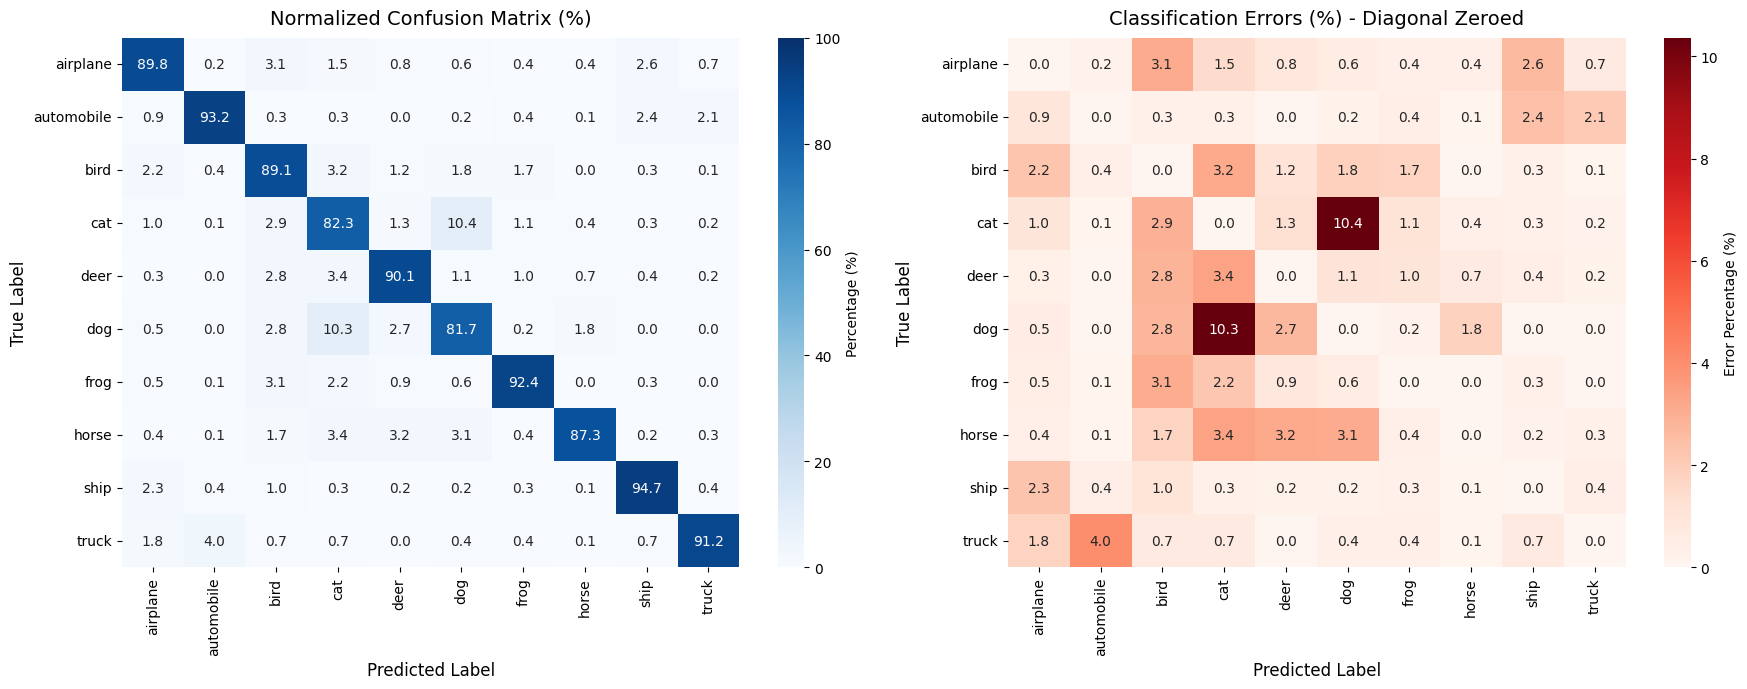

In [ ]:
# let's analyze the errors using confution matrix

from sklearn.metrics import confusion_matrix

class_names = [
    'airplane', 'automobile', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
]

# -------------------------------------------------------------------
# 2. Calculate Percentage Confusion Matrix (Row-Normalized)
# -------------------------------------------------------------------
# Compute raw count confusion matrix
cm_raw = confusion_matrix(true, pred_2)

# Normalize by row sums (actual targets) to get percentages (0.0 to 100.0%)
cm_percent = (cm_raw / cm_raw.sum(axis=1, keepdims=True)) * 100

# -------------------------------------------------------------------
# 3. Create Error Matrix (Zero Out Diagonal)
# -------------------------------------------------------------------
cm_errors = cm_percent.copy()
np.fill_diagonal(cm_errors, 0)

# -------------------------------------------------------------------
# 4. Plot Heatmaps using Seaborn
# -------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# --- Plot 1: Percentage Confusion Matrix ---
sns.heatmap(
    cm_percent,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    vmin=0,
    vmax=100,
    xticklabels=class_names,
    yticklabels=class_names,
    ax=axes[0],
    cbar_kws={'label': 'Percentage (%)'}
)
axes[0].set_title("Normalized Confusion Matrix (%)", fontsize=14, pad=10)
axes[0].set_xlabel("Predicted Label", fontsize=12)
axes[0].set_ylabel("True Label", fontsize=12)

# --- Plot 2: Error Matrix (Diagonal Subtracted/Zeroed) ---
# v_max dynamically set to highlight misclassifications using a warm palette
sns.heatmap(
    cm_errors,
    annot=True,
    fmt=".1f",
    cmap="Reds",
    vmin=0,
    vmax=np.max(cm_errors),
    xticklabels=class_names,
    yticklabels=class_names,
    ax=axes[1],
    cbar_kws={'label': 'Error Percentage (%)'}
)
axes[1].set_title("Classification Errors (%) - Diagonal Zeroed", fontsize=14, pad=10)
axes[1].set_xlabel("Predicted Label", fontsize=12)
axes[1].set_ylabel("True Label", fontsize=12)

plt.tight_layout()
plt.show()

**Some obvious error we can see here:**

-   aeroplane getting misclassified as bird, ship.
-   truck misclassified as automobilies
-   horse misclassified as cat, deer, dog.
-   but most importantly, the category dog and cat.
The error on these two is unusually high compared to other categories.
It looks like the model is finding it difficult to differentiate between these two categories.

This should be intuitive that cats and dogs do share a lot of visual features, just like birds and aeroplanes.

also, fine details vanish in CIFAR10 images as they are tiny (32x32).



